**NOTE :** For a new MRI image, the model produces a probability between 0 and 1.
```
Probability ≥ 0.5 → Tumourous
Probability < 0.5 → Non-Tumourous
```

In [1]:
# import libraries

import os
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow.keras.models import load_model
from PIL import Image
import cv2

print("Libraries imported successfully.")

Libraries imported successfully.


In [4]:
# mount google drive

from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [5]:
# define project paths

PROJECT_DIR = "/content/drive/MyDrive/Brain_Tumor_CNN_Project"
MODELS_DIR = os.path.join(PROJECT_DIR, "models")
RESULTS_DIR = os.path.join(PROJECT_DIR, "results")

BEST_MODEL_PATH = os.path.join(
    MODELS_DIR,
    "best_brain_tumor_cnn.keras"
)
IMG_SIZE = (224, 224)
CLASS_NAMES = {0: "Non-Tumourous", 1: "Tumourous"}

print("Project directory:", PROJECT_DIR)
print("Model path:", BEST_MODEL_PATH)
print("Model exists:", os.path.exists(BEST_MODEL_PATH))

Project directory: /content/drive/MyDrive/Brain_Tumor_CNN_Project
Model path: /content/drive/MyDrive/Brain_Tumor_CNN_Project/models/best_brain_tumor_cnn.keras
Model exists: True


In [6]:
# load the trained CNN model

model = load_model(BEST_MODEL_PATH)

print("Best CNN model loaded successfully.")
print("Input shape:", model.input_shape)
print("Output shape:", model.output_shape)

Best CNN model loaded successfully.
Input shape: (None, 224, 224, 3)
Output shape: (None, 1)


In [7]:
def preprocess_single_image(image_path):
    """
    Loads an MRI image and applies the EXACT same preprocessing
    used during training in Notebook 03.
    """
    # Read and decode
    img = tf.io.read_file(image_path)
    img = tf.image.decode_image(img, channels=3, expand_animations=False)
    img.set_shape([None, None, 3])

    # Resize and Normalize
    img = tf.image.resize(img, IMG_SIZE)
    img = tf.cast(img, tf.float32) / 255.0

    # Add batch dimension [1, 224, 224, 3]
    img = tf.expand_dims(img, axis=0)
    return img

# --- CALLING THE FUNCTION ---
# We test it on a sample image from our test set to verify shape and range
sample_test_img = "/content/drive/MyDrive/Brain_Tumor_CNN_Project/dataset/Epic and CSCR hospital Dataset/Test/notumor/1178.jpg"
processed_sample = preprocess_single_image(sample_test_img)

print(f"Processed Shape: {processed_sample.shape}")
print(f"Pixel Range: [{tf.reduce_min(processed_sample).numpy():.4f}, {tf.reduce_max(processed_sample).numpy():.4f}]")
assert processed_sample.shape == (1, 224, 224, 3), "Shape mismatch!"
print("Preprocessing function verified.")

Processed Shape: (1, 224, 224, 3)
Pixel Range: [0.0000, 0.9346]
Preprocessing function verified.


Why ```expand_dims```?

The CNN expects input in the form : (batch_size, 224, 224, 3)

For one image, we therefore convert it into :(1, 224, 224, 3)

In [8]:
# Prediction Function with Confidence Scoring + Execution Test
def predict_mri(image_path, threshold=0.5):
    """
    Returns prediction label, raw probability, confidence score, and status.
    Includes medical-grade uncertainty flagging.
    """
    processed_img = preprocess_single_image(image_path)
    probability = model.predict(processed_img, verbose=0)[0][0]

    if probability >= threshold:
        predicted_class = 1
        confidence = probability
    else:
        predicted_class = 0
        confidence = 1 - probability

    label = CLASS_NAMES[predicted_class]

    # Medical Uncertainty Flagging
    status = "CONFIDENT"
    if 0.4 <= probability <= 0.6:
        status = "⚠️ UNCERTAIN - REVIEW REQUIRED"
    elif confidence > 0.95:
        status = " HIGH CONFIDENCE"

    return {
        "label": label,
        "probability": float(probability),
        "confidence": float(confidence),
        "status": status,
        "processed_array": processed_img[0].numpy()
    }

In [9]:
test_result = predict_mri(sample_test_img)

print("\nSingle Image Prediction Result:")
print(f"   Class: {test_result['label']}")
print(f"   Raw Probability: {test_result['probability']:.4f}")
print(f"   Confidence: {test_result['confidence']:.2%}")
print(f"   Status: {test_result['status']}")


Single Image Prediction Result:
   Class: Non-Tumourous
   Raw Probability: 0.0148
   Confidence: 98.52%
   Status:  HIGH CONFIDENCE


In [10]:
def get_gradcam_heatmap(model, img_array, last_conv_layer_name='conv2d_3', pred_index=None):
    """
    Generates a Grad-CAM heatmap highlighting tumor regions.
    'conv2d_3' matches the last Conv2D layer in our custom CNN architecture.
    """
    grad_model = tf.keras.models.Model(
        [model.inputs],
        [model.get_layer(last_conv_layer_name).output, model.output]
    )

    with tf.GradientTape() as tape:
        conv_output, predictions = grad_model(img_array)
        if pred_index is None:
            pred_index = tf.argmax(predictions[0])
        class_channel = predictions[:, pred_index]

    grads = tape.gradient(class_channel, conv_output)
    pooled_grads = tf.reduce_mean(grads, axis=(0, 1, 2))

    conv_output = conv_output[0]
    heatmap = conv_output @ pooled_grads[..., tf.newaxis]
    heatmap = tf.squeeze(heatmap)
    heatmap = tf.maximum(heatmap, 0) / tf.math.reduce_max(heatmap)
    return heatmap.numpy()

def overlay_gradcam(original_img, heatmap, alpha=0.4):
    """Overlays JET colormap heatmap onto original image."""
    heatmap = cv2.resize(heatmap, (IMG_SIZE[0], IMG_SIZE[1]))
    heatmap = np.uint8(255 * heatmap)
    heatmap = cv2.applyColorMap(heatmap, cv2.COLORMAP_JET)

    orig_uint8 = np.uint8(original_img * 255)
    superimposed = heatmap * alpha + orig_uint8
    return np.uint8(superimposed)

Sample was Non-Tumourous. Grad-CAM requires a positive tumor prediction.


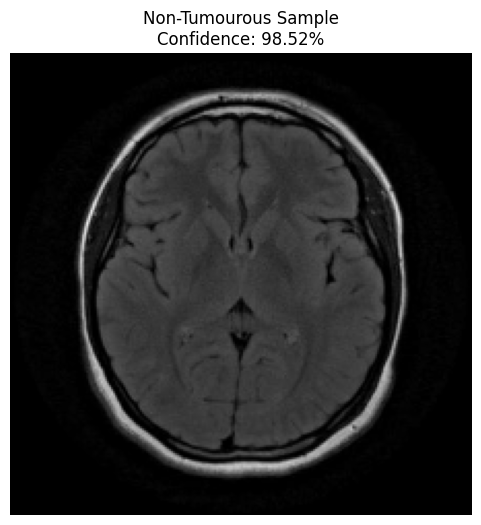

In [11]:
if test_result['label'] == "Tumourous":
    heatmap = get_gradcam_heatmap(model, tf.expand_dims(test_result['processed_array'], 0))
    overlay = overlay_gradcam(test_result['processed_array'], heatmap)

    fig, axes = plt.subplots(1, 3, figsize=(18, 6))
    axes[0].imshow(test_result['processed_array'])
    axes[0].set_title(f"Original\n{test_result['label']}", fontsize=14)
    axes[0].axis('off')

    axes[1].imshow(heatmap, cmap='jet')
    axes[1].set_title("Grad-CAM Heatmap", fontsize=14)
    axes[1].axis('off')

    axes[2].imshow(overlay)
    axes[2].set_title(f"Attention Overlay\n{test_result['status']}", fontsize=14)
    axes[2].axis('off')

    plt.tight_layout()
    plt.show()
else:
    print("Sample was Non-Tumourous. Grad-CAM requires a positive tumor prediction.")
    plt.figure(figsize=(6,6))
    plt.imshow(test_result['processed_array'])
    plt.title(f"Non-Tumourous Sample\nConfidence: {test_result['confidence']:.2%}")
    plt.axis('off')
    plt.show()

In [12]:
import pandas as pd
def run_batch_predictions(csv_path, output_csv_path):
    """
    Runs predictions on an entire CSV of image paths and saves results.
    """
    df = pd.read_csv(csv_path)
    results = []

    print(f"Processing {len(df)} images...")
    for idx, row in df.iterrows():
        try:
            pred = predict_mri(row['image_path'])
            results.append({
                'image_path': row['image_path'],
                'true_label': row.get('label', -1),
                'predicted_label': pred['label'],
                'probability': pred['probability'],
                'confidence': pred['confidence'],
                'status': pred['status']
            })
        except Exception as e:
            print(f"Error processing {row['image_path']}: {e}")

    res_df = pd.DataFrame(results)
    res_df.to_csv(output_csv_path, index=False)
    print(f"Saved {len(res_df)} predictions to {output_csv_path}")
    return res_df

In [13]:
# Note: Ensure you have a test CSV from Notebook 02 or create one here
TEST_CSV_PATH = os.path.join(RESULTS_DIR, "test_split.csv")
OUTPUT_PREDICTIONS_PATH = os.path.join(RESULTS_DIR, "streamlit_predictions.csv")

if os.path.exists(TEST_CSV_PATH):
    predictions_df = run_batch_predictions(TEST_CSV_PATH, OUTPUT_PREDICTIONS_PATH)
    print("\nSample Predictions:")
    display(predictions_df.head())
else:
    print(f" Test CSV not found at {TEST_CSV_PATH}. Run Notebook 02 first.")

Processing 2093 images...
Saved 2093 predictions to /content/drive/MyDrive/Brain_Tumor_CNN_Project/results/streamlit_predictions.csv

Sample Predictions:


,image_path,true_label,predicted_label,probability,confidence,status
0,/content/drive/MyDrive/Brain_Tumor_CNN_Project...,1,Tumourous,0.999427,0.999427,HIGH CONFIDENCE
1,/content/drive/MyDrive/Brain_Tumor_CNN_Project...,1,Tumourous,0.999805,0.999805,HIGH CONFIDENCE
2,/content/drive/MyDrive/Brain_Tumor_CNN_Project...,1,Tumourous,0.999616,0.999616,HIGH CONFIDENCE
3,/content/drive/MyDrive/Brain_Tumor_CNN_Project...,1,Tumourous,0.903415,0.903415,CONFIDENT
4,/content/drive/MyDrive/Brain_Tumor_CNN_Project...,1,Tumourous,0.999984,0.999984,HIGH CONFIDENCE


In [14]:
import matplotlib.pyplot as plt
import numpy as np

def display_prediction(image_path, result):
    """
    Displays the MRI image with prediction overlay.
    Fixed to match the current predict_mri() return dictionary keys.
    """
    try:
        # Load image safely (handles both local and Drive paths)
        img = plt.imread(image_path)

        plt.figure(figsize=(7, 6))
        plt.imshow(img, cmap='gray' if len(img.shape) == 2 else None)
        plt.axis('off')

        # FIX: Use 'label' instead of 'predicted_class'
        # Determine color based on the label string or probability
        is_tumor = "Tumour" in result['label']
        color = 'red' if is_tumor else 'green'

        title_text = f"{result['label']}\nConfidence: {result['confidence']*100:.2f}%"

        plt.title(title_text, color=color, fontsize=14, fontweight='bold', pad=10)
        plt.tight_layout()
        plt.show()

    except Exception as e:
        print(f"️ Error displaying image: {e}")
        print("Falling back to text-only display.")

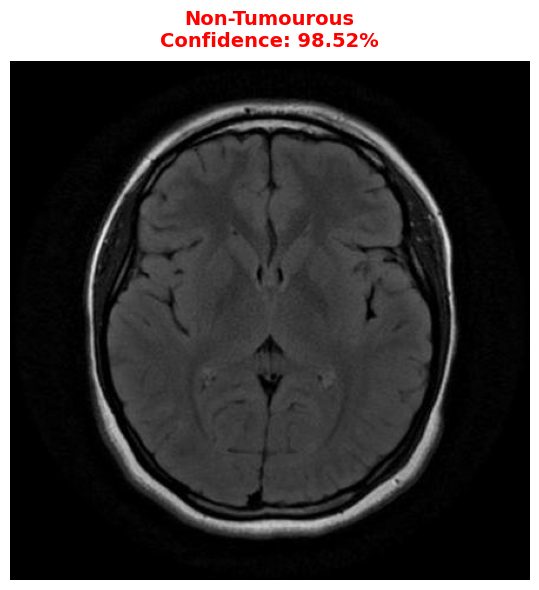


 Detailed Analysis:
   Class      : Non-Tumourous
   Probability: 0.0148
   Confidence : 0.99
   Status     :  HIGH CONFIDENCE


In [15]:
test_image_path = "/content/drive/MyDrive/Brain_Tumor_CNN_Project/dataset/Epic and CSCR hospital Dataset/Test/notumor/1178.jpg"

# Get prediction
result = predict_mri(test_image_path)

# Display visualization
display_prediction(test_image_path, result)

# Print detailed analysis
print(f"\n Detailed Analysis:")
print(f"   Class      : {result['label']}")
print(f"   Probability: {result['probability']:.4f}")
print(f"   Confidence : {result['confidence']:.2f}")
print(f"   Status     : {result['status']}")